In [ ]:
# %pip install tensorflow pandas scikit-learn matplotlib

In [1]:
import tensorflow
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

from sklearn.datasets import load_iris
from keras.utils import to_categorical

In [5]:
#Loading Data

iris=load_iris()

X,Y=iris['data'],iris['target']

Y=to_categorical(Y) #One Hot Classification

X

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#Splitting data into training and testing
x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.2)

In [10]:
#Scaling data

scaler=StandardScaler()
x=5.1
x_train_scaled=scaler.fit_transform(x_train) #Calculates data as z = (x - Mean) / St.Deviation
x_test_scaled=scaler.transform(x_test) #Using transform and not fit_transform so that it calculates mean and st.deviation from training data


In [14]:
y_train.shape

(120, 3)

In [ ]:
#Creating neural network architecture (Build neural network)
model=Sequential([
    Dense(10,activation='relu',input_shape=(x_train_scaled.shape[1],)), # -->Input Layer
    Dense(10,activation='relu'), #-->Hidden Layer
    Dense(y_train.shape[1],activation='softmax')
])

c:\Users\saura\Documents\Python\python_55_days_programs\deep_learning\venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
#Compiling the model
model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

In [25]:
#Training data

history=model.fit(
    x_train_scaled,
    y_train,
    epochs=100,
    batch_size=16,
    validation_data=(x_test_scaled,y_test)
)

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.3333 - loss: 1.4794 - val_accuracy: 0.3667 - val_loss: 1.3843
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3417 - loss: 1.3746 - val_accuracy: 0.3667 - val_loss: 1.3019
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3500 - loss: 1.2809 - val_accuracy: 0.3667 - val_loss: 1.2281
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3583 - loss: 1.1957 - val_accuracy: 0.3667 - val_loss: 1.1615
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3667 - loss: 1.1207 - val_accuracy: 0.3667 - val_loss: 1.1029
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3917 - loss: 1.0615 - val_accuracy: 0.3667 - val_loss: 1.0493
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5000 - loss: 0.9984 - val_accuracy: 0.4667 - val_loss: 1.0031
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5917 - loss: 0.9469 - val_accuracy: 0.6000 - val_loss:

In [41]:
history

In [31]:
model.layers[2].get_weights()

[array([[-0.24215956,  0.1311164 ,  0.45896092],
        [ 0.6522213 , -0.51618624, -0.0980478 ],
        [ 0.04976655,  0.22624362,  0.92352927],
        [-0.27271274, -0.40777615,  0.45001936],
        [-0.79040265, -0.38616782,  0.20735973],
        [-0.6448367 ,  1.0029604 , -0.2120418 ],
        [ 0.47402567, -0.7409335 , -0.29515156],
        [-0.19098541,  0.9189629 ,  0.19638684],
        [-0.35909203, -0.68254495,  0.46291363],
        [ 0.06396471,  1.0513494 , -1.0784119 ]], dtype=float32),
 array([-0.17035829,  0.2893832 , -0.12803078], dtype=float32)]

In [34]:
#Evaluate

loss,accuracy=model.evaluate(x_test_scaled,y_test)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 1.0000 - loss: 0.0926


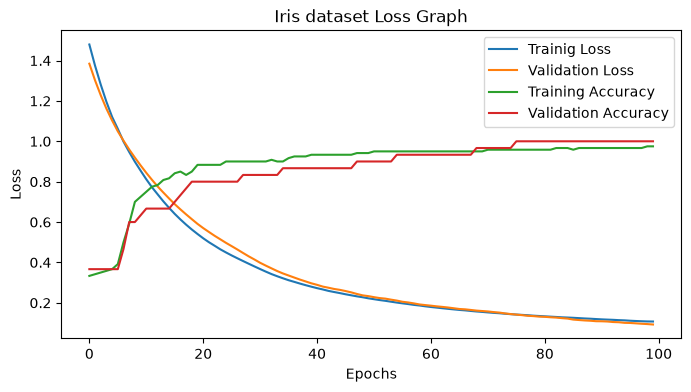

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
plt.plot(history.history['loss'],label='Trainig Loss')
plt.plot(history.history['val_loss'],label='Validation Loss')
plt.plot(history.history['accuracy'],label="Training Accuracy")
plt.plot(history.history['val_accuracy'],label="Validation Accuracy")
plt.title("Iris dataset Loss Graph")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()